In [10]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from PIL import Image
import os
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.metrics import confusion_matrix
import seaborn as sns

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


## Residual U-Net (ResUNet) Architecture
U-Net with the same widths and dropout placement as the plain U-Net, but every double-conv block is a residual block (identity / 1x1-conv shortcut).

In [11]:
class ResBlock(nn.Module):
    """Residual double-conv block:
        out = ReLU( BN(Conv3x3( [Drop]( ReLU(BN(Conv3x3(x))) ) )) + shortcut(x) ) [-> Drop]
    shortcut = identity when in_ch == out_ch, otherwise 1x1 Conv + BN.
    Dropout sits at the same places as in the plain U-Net DoubleConv (after the first ReLU and at the block end)."""
    def __init__(self, in_ch, out_ch, dropout_rate=0.1, use_dropout=True):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )
        self.drop1 = nn.Dropout2d(dropout_rate) if use_dropout else nn.Identity()
        self.conv2 = nn.Sequential(
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
        )
        if in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=1, bias=False),
                nn.BatchNorm2d(out_ch),
            )
        else:
            self.shortcut = nn.Identity()
        self.relu = nn.ReLU(inplace=True)
        self.drop2 = nn.Dropout2d(dropout_rate) if use_dropout else nn.Identity()

    def forward(self, x):
        out = self.conv1(x)
        out = self.drop1(out)
        out = self.conv2(out)
        out = self.relu(out + self.shortcut(x))
        return self.drop2(out)

class ResUNet(nn.Module):
    """Residual U-Net: same layout / widths / dropout placement as U-Net (UNet4),
    but every DoubleConv is replaced by a ResBlock (residual connection inside each block)."""
    def __init__(self, in_channels=3, out_channels=1, features=[32, 64, 128, 256], dropout_rate=0.15):
        super().__init__()

        self.enc1 = ResBlock(in_channels, features[0], dropout_rate, use_dropout=False)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = ResBlock(features[0], features[1], dropout_rate, use_dropout=False)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = ResBlock(features[1], features[2], dropout_rate, use_dropout=False)
        self.pool3 = nn.MaxPool2d(2)
        self.enc4 = ResBlock(features[2], features[3], dropout_rate=0.15, use_dropout=True)
        self.pool4 = nn.MaxPool2d(2)

        self.bottleneck = ResBlock(features[3], features[3]*2, dropout_rate=0.2, use_dropout=True)

        self.up4 = nn.ConvTranspose2d(features[3]*2, features[3], kernel_size=2, stride=2)
        self.dec4 = ResBlock(features[3]*2, features[3], dropout_rate, use_dropout=True)
        self.up3 = nn.ConvTranspose2d(features[3], features[2], kernel_size=2, stride=2)
        self.dec3 = ResBlock(features[2]*2, features[2], dropout_rate, use_dropout=True)
        self.up2 = nn.ConvTranspose2d(features[2], features[1], kernel_size=2, stride=2)
        self.dec2 = ResBlock(features[1]*2, features[1], dropout_rate, use_dropout=True)
        self.up1 = nn.ConvTranspose2d(features[1], features[0], kernel_size=2, stride=2)
        self.dec1 = ResBlock(features[0]*2, features[0], dropout_rate, use_dropout=True)

        self.final_conv = nn.Conv2d(features[0], out_channels, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x); p1 = self.pool1(e1)
        e2 = self.enc2(p1); p2 = self.pool2(e2)
        e3 = self.enc3(p2); p3 = self.pool3(e3)
        e4 = self.enc4(p3); p4 = self.pool4(e4)

        b = self.bottleneck(p4)

        d4 = self.up4(b); d4 = torch.cat([d4, e4], dim=1); d4 = self.dec4(d4)
        d3 = self.up3(d4); d3 = torch.cat([d3, e3], dim=1); d3 = self.dec3(d3)
        d2 = self.up2(d3); d2 = torch.cat([d2, e2], dim=1); d2 = self.dec2(d2)
        d1 = self.up1(d2); d1 = torch.cat([d1, e1], dim=1); d1 = self.dec1(d1)

        return self.final_conv(d1)


## Dataset and Data Loading

In [12]:
IMG_EXTS = ('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff')

def find_pv01_pairs(root_dir):
    """Walk root_dir and pair every 'NAME.<ext>' image with its 'NAME_label.<ext>' mask.
    Returns {group_name: [(image_path, label_path), ...]} where group_name is the
    rooftop folder (PV01_Rooftop_Brick, PV01_Rooftop_FlatConcrete, ...)."""
    groups = {}
    for folder, _, files in sorted(os.walk(root_dir)):
        by_stem = {os.path.splitext(f)[0]: f for f in sorted(files) if f.lower().endswith(IMG_EXTS)}
        rel = os.path.relpath(folder, root_dir)
        group = rel.split(os.sep)[0]
        for stem, fname in by_stem.items():
            if stem.endswith('_label'):
                continue
            lbl = by_stem.get(stem + '_label')
            if lbl is not None:
                groups.setdefault(group, []).append((os.path.join(folder, fname), os.path.join(folder, lbl)))
    return groups

def build_pv01_splits(root_dir, val_frac=0.15, test_frac=0.15, seed=42):
    """PV01 ships without a train/val/test split, so make a fixed, seeded one.
    The split is done per rooftop folder so all three types appear in every split."""
    groups = find_pv01_pairs(root_dir)
    assert len(groups) > 0, f"No image/_label pairs found under {root_dir}"
    rng = np.random.RandomState(seed)
    train, val, test = [], [], []
    for g in sorted(groups):
        pairs = groups[g]
        idx = rng.permutation(len(pairs))
        n_test = int(round(len(pairs) * test_frac))
        n_val = int(round(len(pairs) * val_frac))
        test += [pairs[i] for i in idx[:n_test]]
        val += [pairs[i] for i in idx[n_test:n_test + n_val]]
        train += [pairs[i] for i in idx[n_test + n_val:]]
        print(f"{g}: {len(pairs)} pairs")
    return train, val, test

class PV01Dataset(Dataset):
    def __init__(self, pairs, transform=None, img_size=(256, 256)):
        self.pairs = pairs
        self.transform = transform
        self.img_size = img_size

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        img_path, label_path = self.pairs[idx]

        img = Image.open(img_path).convert('RGB').resize(self.img_size)
        label = Image.open(label_path).convert('L').resize(self.img_size, Image.NEAREST)

        if self.transform:
            img = self.transform(img)
        else:
            img = transforms.ToTensor()(img)

        # binary mask: any non-zero pixel is solar panel (works for 0/255 and 0/1 masks)
        label = torch.from_numpy((np.array(label) > 0).astype(np.float32)).unsqueeze(0)

        return img, label


## Loss Functions and Metrics

In [13]:
def dice_coef(pred, target, smooth=1e-6):
    pred = pred.contiguous()
    target = target.contiguous()
    intersection = (pred * target).sum(dim=(2,3))
    denom = pred.sum(dim=(2,3)) + target.sum(dim=(2,3))
    dice = (2. * intersection + smooth) / (denom + smooth)
    return dice.mean()

class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def forward(self, pred, target):
        dice = dice_coef(pred, target, smooth=self.smooth)
        return 1.0 - dice

def combined_loss(logits, mask, bce_weight=0.6, dice_weight=0.4):
    bce_loss = nn.BCEWithLogitsLoss()
    bce = bce_loss(logits, mask)
    probs = torch.sigmoid(logits)
    dice = DiceLoss()(probs, mask)
    return bce_weight * bce + dice_weight * dice

@torch.no_grad()
def compute_metrics_batch(logits, masks, thresh=0.5):
    probs = torch.sigmoid(logits)
    preds = (probs >= thresh).float()
    preds_flat = preds.view(-1).cpu().numpy()
    masks_flat = masks.view(-1).cpu().numpy()
    
    unique_preds = np.unique(preds_flat)
    unique_masks = np.unique(masks_flat)
    
    if len(unique_preds) == 1 and len(unique_masks) == 1:
        if unique_preds[0] == unique_masks[0]:
            if unique_preds[0] == 1:
                tp, fp, fn, tn = len(preds_flat), 0, 0, 0
            else:
                tp, fp, fn, tn = 0, 0, 0, len(preds_flat)
        else:
            if unique_preds[0] == 1:
                tp, fp, fn, tn = 0, len(preds_flat), 0, 0
            else:
                tp, fp, fn, tn = 0, 0, len(preds_flat), 0
    else:
        cm = confusion_matrix(masks_flat, preds_flat, labels=[0,1])
        if cm.shape == (2, 2):
            tn, fp, fn, tp = cm.ravel()
        else:
            if cm.shape == (1, 1):
                if unique_masks[0] == 0:
                    tn, fp, fn, tp = cm[0,0], 0, 0, 0
                else:
                    tn, fp, fn, tp = 0, 0, 0, cm[0,0]
            else:
                tn, fp, fn, tp = 0, 0, 0, 0
    
    eps = 1e-8
    iou = tp / (tp + fp + fn + eps)
    dice = (2 * tp) / (2 * tp + fp + fn + eps)
    precision = tp / (tp + fp + eps)
    recall = tp / (tp + fn + eps)
    f1 = 2 * precision * recall / (precision + recall + eps)
    acc = (tp + tn) / (tp + tn + fp + fn + eps)
    
    iou_background = tn / (tn + fp + fn + eps)
    iou_damage = tp / (tp + fp + fn + eps)
    miou = (iou_background + iou_damage) / 2
    
    return {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
            "iou": float(iou), "dice": float(dice), "precision": float(precision),
            "recall": float(recall), "f1": float(f1), "acc": float(acc), "miou": float(miou)}

## Training and Validation Functions

In [14]:
import copy

class EarlyStopping:
    def __init__(self, patience=10, min_delta=1e-4, restore_best_weights=True):
        self.patience = patience
        self.min_delta = min_delta
        self.restore_best_weights = restore_best_weights
        self.best_loss = None
        self.counter = 0
        self.best_weights = None
        
    def __call__(self, val_loss, model):
        if self.best_loss is None:
            self.best_loss = val_loss
            self.save_checkpoint(model)
        elif self.best_loss - val_loss > self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
            self.save_checkpoint(model)
        else:
            self.counter += 1
            
        if self.counter >= self.patience:
            if self.restore_best_weights:
                model.load_state_dict(self.best_weights)
            return True
        return False
    
    def save_checkpoint(self, model):
        self.best_weights = copy.deepcopy(model.state_dict())

def train_one_epoch(model, loader, optimizer):
    model.train()
    running_loss = 0.0
    agg = {"tn":0,"fp":0,"fn":0,"tp":0}
    
    for imgs, masks in tqdm(loader, desc="Train batch"):
        imgs = imgs.to(device)
        masks = masks.to(device)
        optimizer.zero_grad()
        logits = model(imgs)
        loss = combined_loss(logits, masks)
        loss.backward()
        
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        optimizer.step()
        running_loss += loss.item() * imgs.size(0)
        
        mets = compute_metrics_batch(logits, masks)
        for k in ["tn","fp","fn","tp"]:
            agg[k] += mets[k]
    
    tp, fp, fn, tn = agg["tp"], agg["fp"], agg["fn"], agg["tn"]
    train_acc = (tp + tn) / (tp + tn + fp + fn + 1e-8)
    
    epoch_loss = running_loss / len(loader.dataset)
    return epoch_loss, train_acc

@torch.no_grad()
def validate(model, loader):
    model.eval()
    running_loss = 0.0
    agg = {"tn":0,"fp":0,"fn":0,"tp":0}
    
    for imgs, masks in tqdm(loader, desc="Val batch"):
        imgs = imgs.to(device)
        masks = masks.to(device)
        logits = model(imgs)
        loss = combined_loss(logits, masks)
        running_loss += loss.item() * imgs.size(0)
        mets = compute_metrics_batch(logits, masks)
        for k in ["tn","fp","fn","tp"]:
            agg[k] += mets[k]
    
    tp, fp, fn, tn = agg["tp"], agg["fp"], agg["fn"], agg["tn"]
    eps = 1e-8
    iou = tp / (tp + fp + fn + eps)
    dice = (2 * tp) / (2 * tp + fp + fn + eps)
    precision = tp / (tp + fp + eps)
    recall = tp / (tp + fn + eps)
    f1 = 2 * precision * recall / (precision + recall + eps)
    acc = (tp + tn) / (tp + tn + fp + fn + eps)
    
    iou_background = tn / (tn + fp + fn + eps)
    iou_damage = tp / (tp + fp + fn + eps)
    miou = (iou_background + iou_damage) / 2
    
    epoch_loss = running_loss / len(loader.dataset)
    metrics = {"loss": epoch_loss, "iou": iou, "dice": dice, "precision": precision,
               "recall": recall, "f1": f1, "acc": acc, "miou": miou,
               "confusion": np.array([[tn, fp], [fn, tp]])}
    return metrics

def train_model(model, train_loader, val_loader, num_epochs=200, learning_rate=2e-4, patience=10):
    decay, no_decay = [], []
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if p.ndim == 1 or name.endswith(".bias"):
            no_decay.append(p)
        else:
            decay.append(p)

    optimizer = optim.AdamW(
        [
            {"params": decay, "weight_decay": 1e-2},
            {"params": no_decay, "weight_decay": 0.0},
        ],
        lr=learning_rate,
    )
    
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.7, patience=7, min_lr=1e-6
    )
    
    early_stopping = EarlyStopping(patience=patience, min_delta=1e-4)
    
    train_losses = []
    val_losses = []
    val_ious = []
    val_dices = []
    train_accs = []
    val_accs = []
    
    best_val_loss = float('inf')
    
    for epoch in range(num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}")
        
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer)
        
        val_metrics = validate(model, val_loader)
        
        scheduler.step(val_metrics['loss'])
        
        print(f"Train Loss: {train_loss:.6f} | Train Acc: {train_acc:.4f}")
        print(f"Val Loss: {val_metrics['loss']:.6f} | Val Acc: {val_metrics['acc']:.4f} | IoU: {val_metrics['iou']:.4f} | Dice: {val_metrics['dice']:.4f} | F1: {val_metrics['f1']:.4f}")
        print(f"Learning Rate: {optimizer.param_groups[0]['lr']:.2e}")
        
        train_losses.append(train_loss)
        val_losses.append(val_metrics['loss'])
        val_ious.append(val_metrics['iou'])
        val_dices.append(val_metrics['dice'])
        train_accs.append(train_acc)
        val_accs.append(val_metrics['acc'])
        
        if val_metrics['loss'] < best_val_loss - 1e-4:
            best_val_loss = val_metrics['loss']
            torch.save(model.state_dict(), 'PV01_ResUNet.pth')
            print(f"Saved best model with validation loss: {best_val_loss:.6f}")
        
        if early_stopping(val_metrics['loss'], model):
            print(f'Early stopping triggered after {epoch+1} epochs')
            break
    
    return train_losses, val_losses, val_ious, val_dices, train_accs, val_accs

## Training Configuration and Execution


In [15]:
def main():
    # Hyperparameters
    BATCH_SIZE = 5
    LEARNING_RATE = 2e-4
    NUM_EPOCHS = 200
    PATIENCE = 10
    IMG_SIZE = (256, 256)
    
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    
    # folder that contains PV01_Rooftop_Brick, PV01_Rooftop_FlatConcrete, PV01_Rooftop_SteelTile
    # (if this path errors, use the copy-path icon in Kaggle's Input panel)
    root_dir = "/kaggle/input/datasets/chinnuuuuu/pv01dataset/PV01/PV01"
    
    # PV01 ships without a split, so build a fixed seeded one (per rooftop folder)
    train_pairs, val_pairs, test_pairs = build_pv01_splits(root_dir, val_frac=0.15, test_frac=0.15, seed=42)
    train_dataset = PV01Dataset(train_pairs, transform=transform, img_size=IMG_SIZE)
    val_dataset = PV01Dataset(val_pairs, transform=transform, img_size=IMG_SIZE)
    test_dataset = PV01Dataset(test_pairs, transform=transform, img_size=IMG_SIZE)
    
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
    val_loader = DataLoader(val_dataset, batch_size=2, shuffle=False, num_workers=0, pin_memory=True)
    test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=0, pin_memory=True)
    
    print(f"Training samples: {len(train_dataset)}")
    print(f"Validation samples: {len(val_dataset)}")
    print(f"Test samples: {len(test_dataset)}")
    
    # dropout as U-Net: encoder block 4 = 0.15, bottleneck = 0.2, decoder = 0.15 (built into the model)
    FEATURES = [32, 64, 128, 256]
    DROPOUT_RATE = 0.15
    
    model = ResUNet(in_channels=3, out_channels=1, features=FEATURES, dropout_rate=DROPOUT_RATE).to(device)
    
    total_params = sum(p.numel() for p in model.parameters())
    print(f"Total parameters: {total_params:,}")
    
    print("\nStarting ResUNet training")
    print(f"Learning Rate: {LEARNING_RATE}")
    print(f"Weight Decay: 1e-3")
    print(f"Dropout: enc4=0.15, bottleneck=0.2, decoder={DROPOUT_RATE}")
    print(f"Threshold: 0.5")
    print(f"Scheduler: ReduceLROnPlateau (factor=0.7, patience=7)\n")
    
    train_losses, val_losses, val_ious, val_dices, train_accs, val_accs = train_model(
        model, train_loader, val_loader, NUM_EPOCHS, LEARNING_RATE, PATIENCE
    )
    
    return model, train_losses, val_losses, val_ious, val_dices, train_accs, val_accs, test_loader

model, train_losses, val_losses, val_ious, val_dices, train_accs, val_accs, test_loader = main()

PV01_Rooftop_Brick: 138 pairs
PV01_Rooftop_FlatConcrete: 413 pairs
PV01_Rooftop_SteelTile: 94 pairs
Training samples: 451
Validation samples: 97
Test samples: 97
Total parameters: 8,114,241

Starting ResUNet training
Learning Rate: 0.0002
Weight Decay: 1e-3
Dropout: enc4=0.15, bottleneck=0.2, decoder=0.15
Threshold: 0.5
Scheduler: ReduceLROnPlateau (factor=0.7, patience=7)


Epoch 1/200


Val batch: 100%|██████████| 49/49 [00:01<00:00, 39.98it/s]


Train Loss: 0.462822 | Train Acc: 0.8213
Val Loss: 0.296294 | Val Acc: 0.9397 | IoU: 0.8273 | Dice: 0.9055 | F1: 0.9055
Learning Rate: 2.00e-04
Saved best model with validation loss: 0.296294

Epoch 2/200


Val batch: 100%|██████████| 49/49 [00:01<00:00, 39.06it/s]


Train Loss: 0.316212 | Train Acc: 0.9318
Val Loss: 0.230881 | Val Acc: 0.9593 | IoU: 0.8761 | Dice: 0.9339 | F1: 0.9339
Learning Rate: 2.00e-04
Saved best model with validation loss: 0.230881

Epoch 3/200


...

Train Loss: 0.045026 | Train Acc: 0.9843
Val Loss: 0.061876 | Val Acc: 0.9811 | IoU: 0.9390 | Dice: 0.9686 | F1: 0.9686
Learning Rate: 1.40e-04

Epoch 49/200


Val batch: 100%|██████████| 49/49 [00:01<00:00, 40.17it/s]


Train Loss: 0.044021 | Train Acc: 0.9846
Val Loss: 0.060717 | Val Acc: 0.9815 | IoU: 0.9396 | Dice: 0.9689 | F1: 0.9689
Learning Rate: 1.40e-04

Epoch 50/200


Val batch: 100%|██████████| 49/49 [00:01<00:00, 39.27it/s]

Train Loss: 0.051736 | Train Acc: 0.9835
Val Loss: 0.065707 | Val Acc: 0.9811 | IoU: 0.9381 | Dice: 0.9681 | F1: 0.9681
Learning Rate: 1.40e-04
Early stopping triggered after 50 epochs


## Visualization of Training Progress

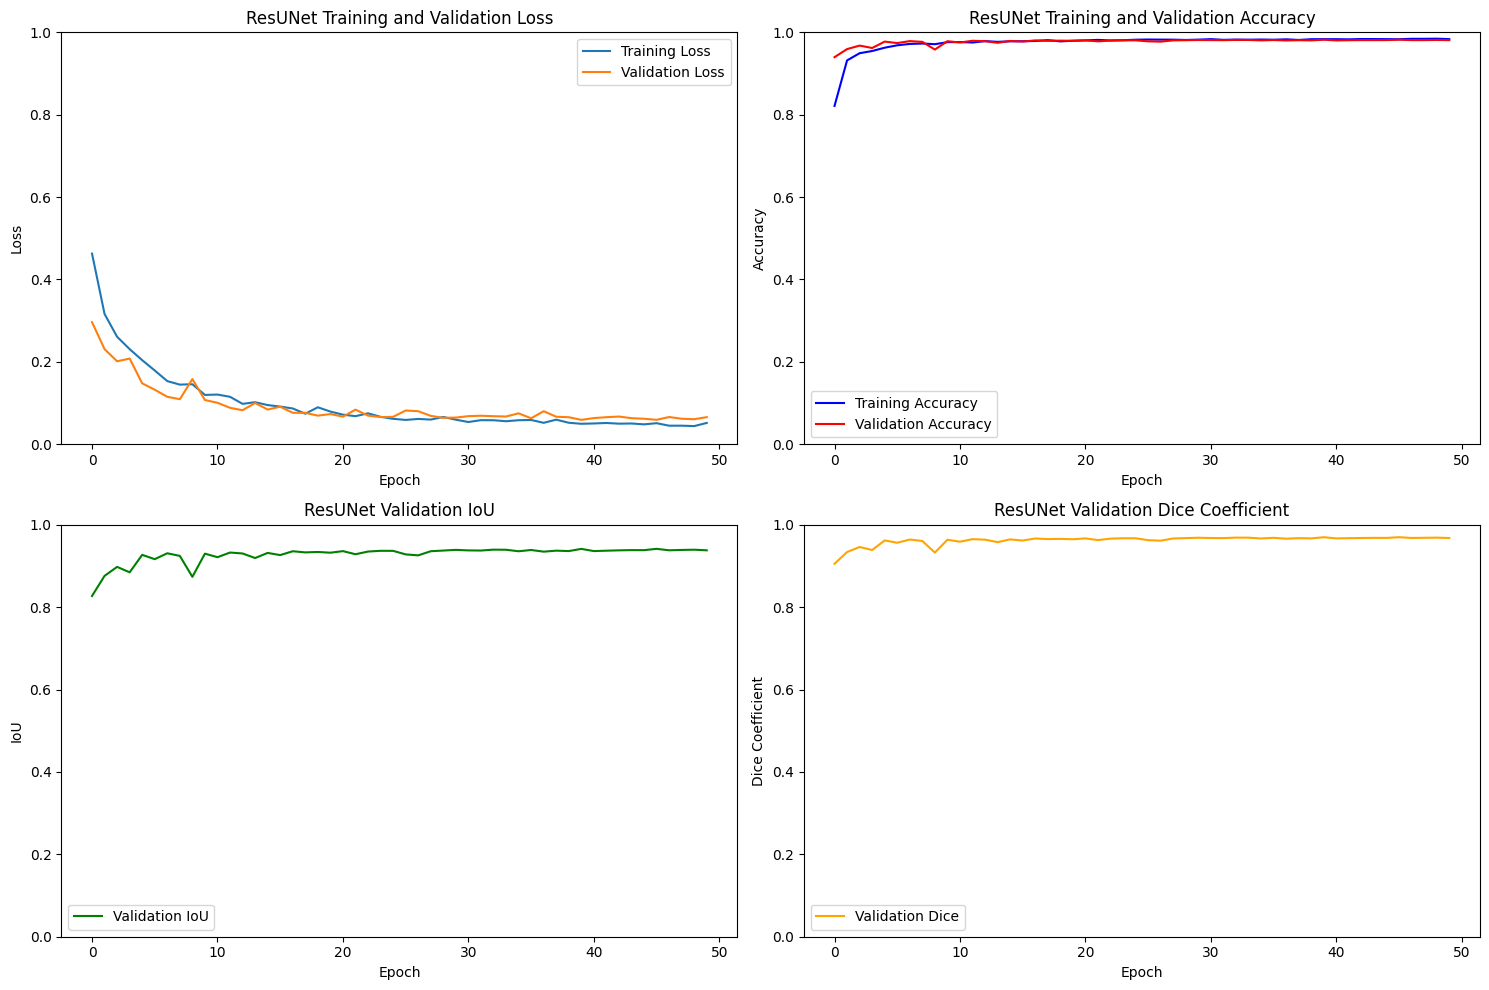

In [16]:
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 10))

ax1.plot(train_losses, label='Training Loss')
ax1.plot(val_losses, label='Validation Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_ylim(0, 1)
ax1.legend()
ax1.set_title('ResUNet Training and Validation Loss')

ax2.plot(train_accs, label='Training Accuracy', color='blue')
ax2.plot(val_accs, label='Validation Accuracy', color='red')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.set_ylim(0, 1)
ax2.legend()
ax2.set_title('ResUNet Training and Validation Accuracy')

ax3.plot(val_ious, label='Validation IoU', color='green')
ax3.set_xlabel('Epoch')
ax3.set_ylabel('IoU')
ax3.set_ylim(0, 1)
ax3.legend()
ax3.set_title('ResUNet Validation IoU')

ax4.plot(val_dices, label='Validation Dice', color='orange')
ax4.set_xlabel('Epoch')
ax4.set_ylabel('Dice Coefficient')
ax4.set_ylim(0, 1)
ax4.legend()
ax4.set_title('ResUNet Validation Dice Coefficient')

plt.tight_layout()
plt.savefig('PV01_ResUNet_training_curves.png', dpi=300, bbox_inches='tight')
plt.show()

## Test Evaluation

Loading best ResUNet model for test evaluation...

Evaluating ResUNet on test set...


Val batch: 100%|██████████| 97/97 [00:01<00:00, 56.22it/s]



U-NET++ TEST EVALUATION METRICS
Configuration: ResUNet | dropout as U-Net: encoder block 4 = 0.15, bottleneck = 0.2, decoder = 0.15
Test set processed with batch_size=1
Loss:            0.051855
IoU:             0.9442
mIoU:            0.9628
Dice Coefficient: 0.9713
Accuracy:        0.9858
Precision:       0.9690
Recall:          0.9737
F1-Score:        0.9713
Confusion matrix (pixel-level):
[[4741172   48860]
 [  41271 1525689]]


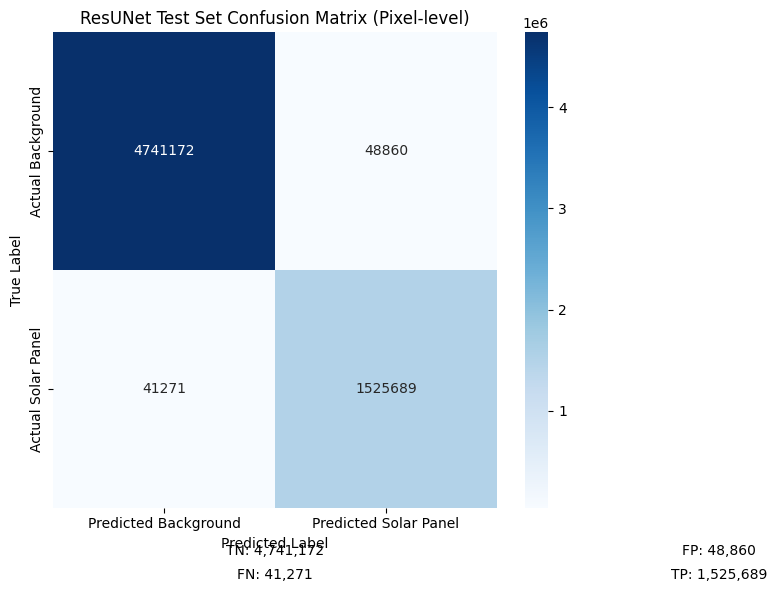

ResUNet training and evaluation completed!


In [17]:
print("Loading best ResUNet model for test evaluation...")
model.load_state_dict(torch.load('PV01_ResUNet.pth', map_location=device))
model.to(device)

print("\nEvaluating ResUNet on test set...")
test_metrics = validate(model, test_loader)

print("\n" + "="*50)
print("U-NET++ TEST EVALUATION METRICS")
print("Configuration: ResUNet | dropout as U-Net: encoder block 4 = 0.15, bottleneck = 0.2, decoder = 0.15")
print("="*50)
print(f"Test set processed with batch_size=1")
print(f"Loss:            {test_metrics['loss']:.6f}")
print(f"IoU:             {test_metrics['iou']:.4f}")
print(f"mIoU:            {test_metrics['miou']:.4f}")
print(f"Dice Coefficient: {test_metrics['dice']:.4f}")
print(f"Accuracy:        {test_metrics['acc']:.4f}")
print(f"Precision:       {test_metrics['precision']:.4f}")
print(f"Recall:          {test_metrics['recall']:.4f}")
print(f"F1-Score:        {test_metrics['f1']:.4f}")
print("Confusion matrix (pixel-level):")
print(test_metrics["confusion"])
print("="*50)

plt.figure(figsize=(8, 6))
cm = test_metrics["confusion"]
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Predicted Background', 'Predicted Solar Panel'],
            yticklabels=['Actual Background', 'Actual Solar Panel'])
plt.title('ResUNet Test Set Confusion Matrix (Pixel-level)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')

plt.text(0.5, -0.1, f'TN: {cm[0,0]:,}', ha='center', transform=plt.gca().transAxes)
plt.text(1.5, -0.1, f'FP: {cm[0,1]:,}', ha='center', transform=plt.gca().transAxes)
plt.text(0.5, -0.15, f'FN: {cm[1,0]:,}', ha='center', transform=plt.gca().transAxes)
plt.text(1.5, -0.15, f'TP: {cm[1,1]:,}', ha='center', transform=plt.gca().transAxes)

plt.tight_layout()
plt.savefig('PV01_ResUNet_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

print("ResUNet training and evaluation completed!")


## Test the model on images

PV01_Rooftop_Brick: 138 pairs
PV01_Rooftop_FlatConcrete: 413 pairs
PV01_Rooftop_SteelTile: 94 pairs


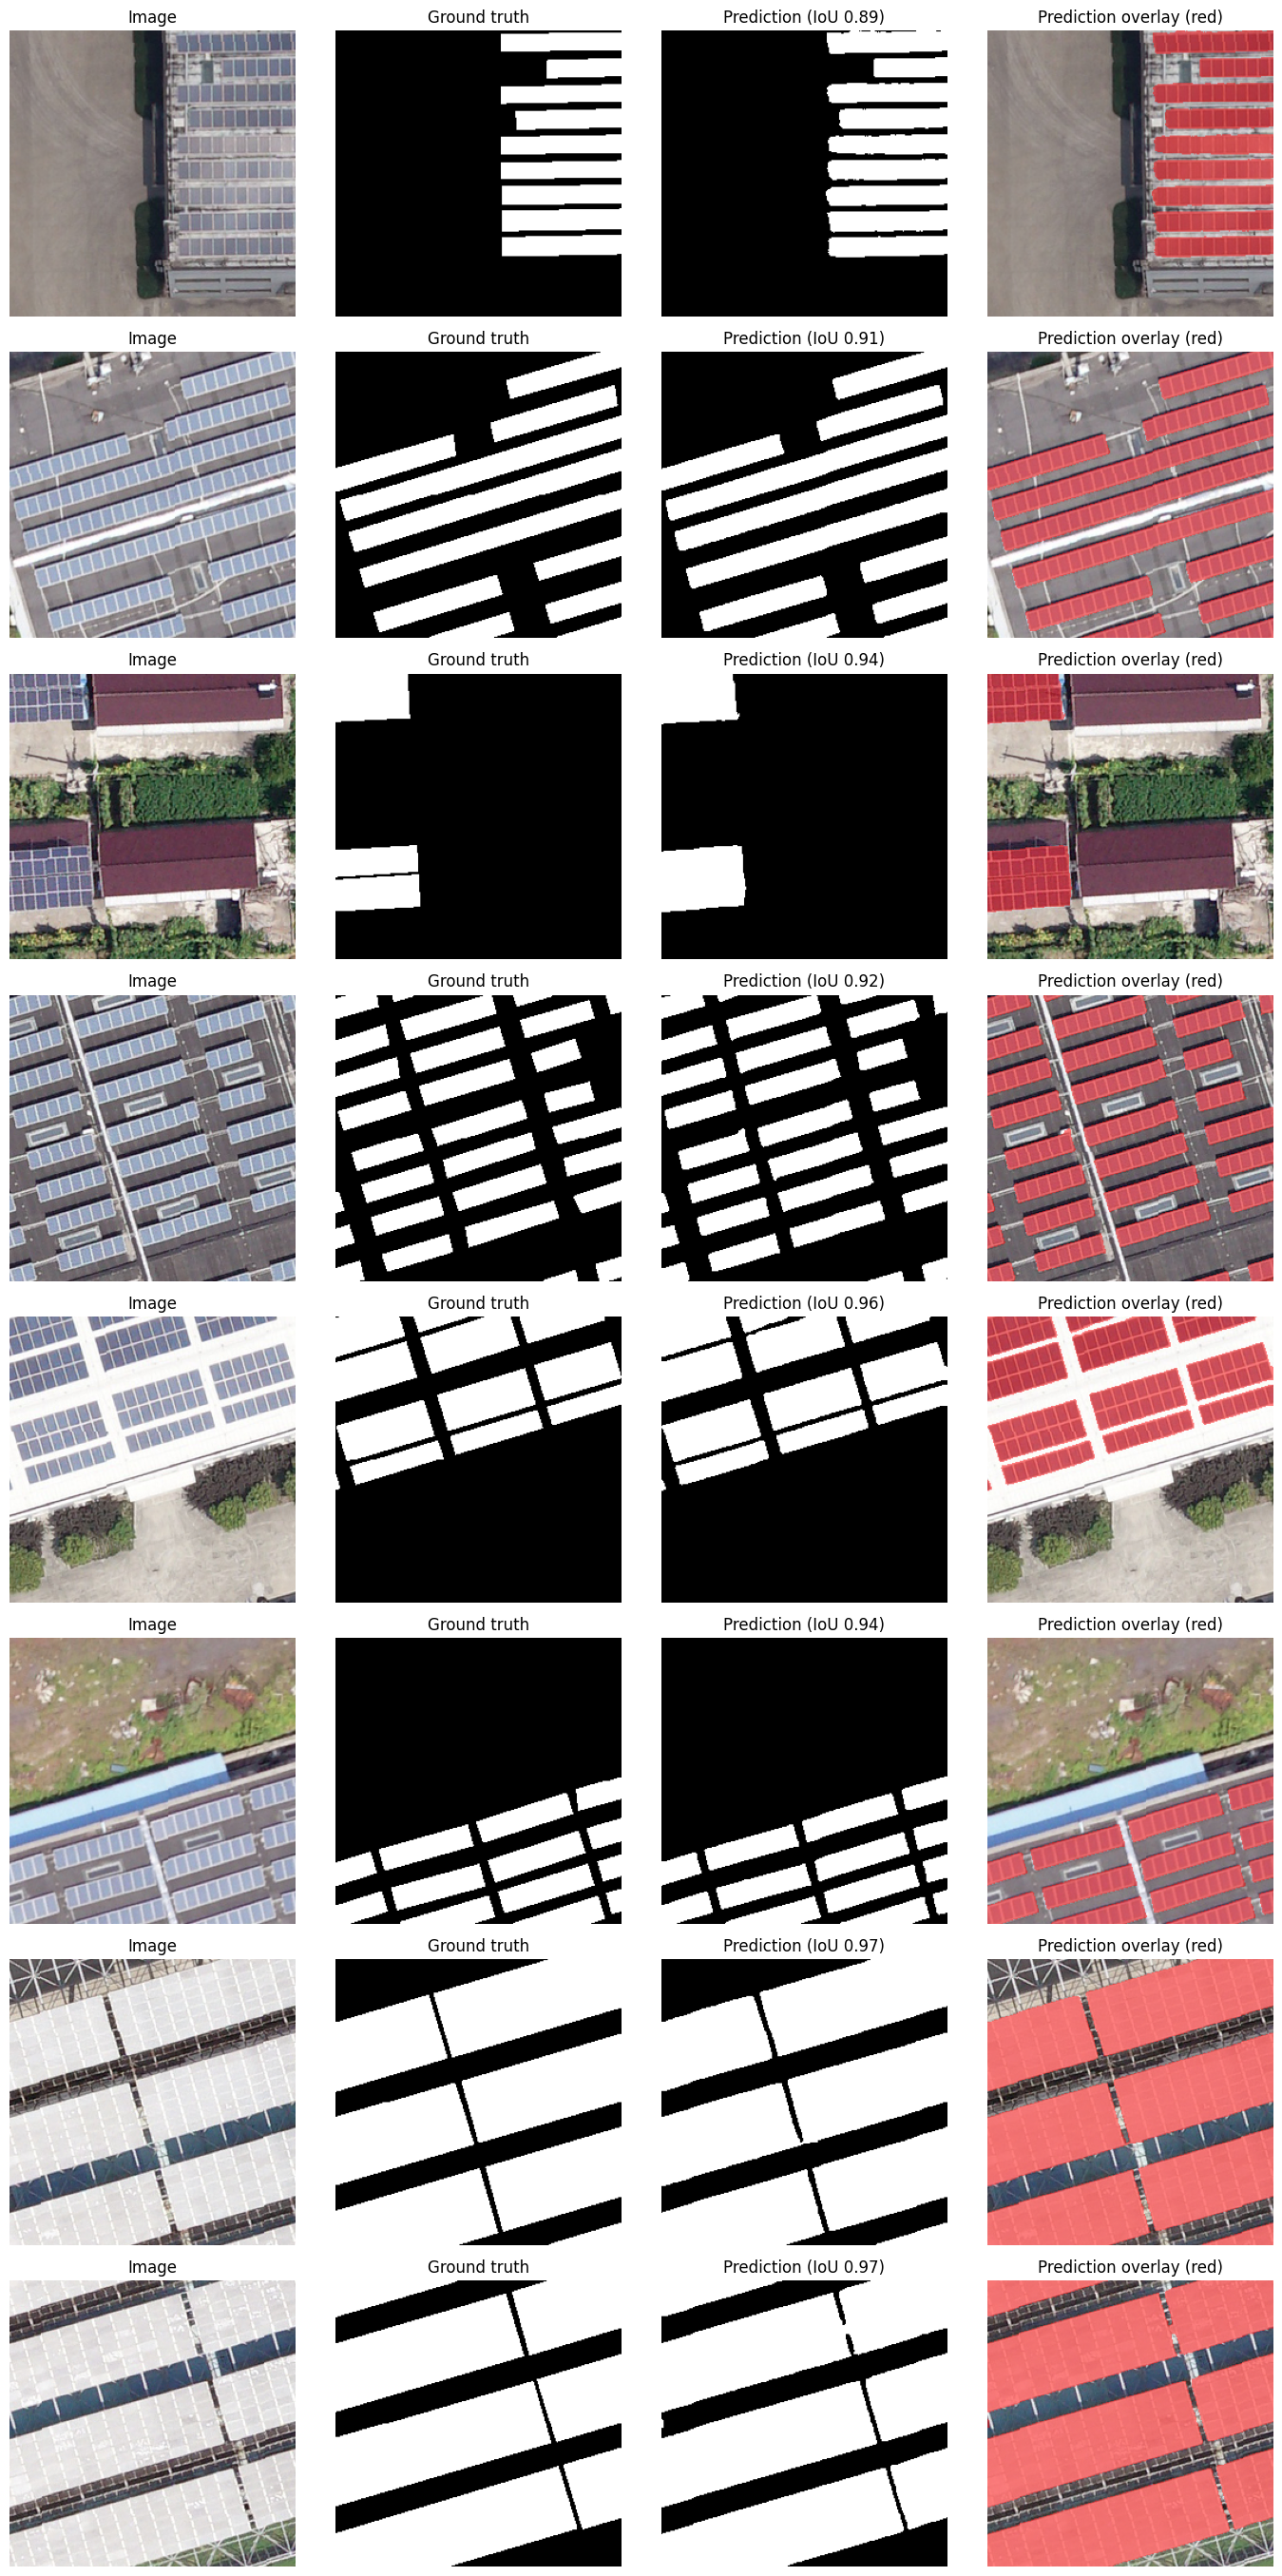

In [18]:
import random

root_dir = '/kaggle/input/datasets/chinnuuuuu/pv01dataset/PV01/PV01'
IMG_SIZE = (256, 256)
FEATURES = [32, 64, 128, 256]
DROPOUT_RATE = 0.15
CKPT = 'PV01_ResUNet.pth'

# rebuild the test set and load the best checkpoint
tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
_, _, test_pairs = build_pv01_splits(root_dir, val_frac=0.15, test_frac=0.15, seed=42)
test_ds = PV01Dataset(test_pairs, transform=tf, img_size=IMG_SIZE)

net = ResUNet(in_channels=3, out_channels=1, features=FEATURES, dropout_rate=DROPOUT_RATE).to(device)
net.load_state_dict(torch.load(CKPT, map_location=device))
net.eval()

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def show_predictions(n=8, seed=0, thresh=0.5):
    random.seed(seed)
    idxs = random.sample(range(len(test_ds)), n)
    fig, axes = plt.subplots(n, 4, figsize=(14, 3.4 * n))
    for r, i in enumerate(idxs):
        img, gt = test_ds[i]
        with torch.no_grad():
            prob = torch.sigmoid(net(img.unsqueeze(0).to(device)))[0, 0].cpu()
        pred = (prob >= thresh).float()

        rgb = (img * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
        gt_np, pred_np = gt[0].numpy(), pred.numpy()

        inter = (gt_np * pred_np).sum()
        union = gt_np.sum() + pred_np.sum() - inter
        iou = inter / union if union > 0 else float('nan')

        overlay = rgb.copy()
        overlay[pred_np > 0] = 0.5 * overlay[pred_np > 0] + 0.5 * np.array([1, 0, 0])

        axes[r, 0].imshow(rgb);                  axes[r, 0].set_title("Image")
        axes[r, 1].imshow(gt_np, cmap='gray');   axes[r, 1].set_title("Ground truth")
        axes[r, 2].imshow(pred_np, cmap='gray'); axes[r, 2].set_title(f"Prediction (IoU {iou:.2f})")
        axes[r, 3].imshow(overlay);              axes[r, 3].set_title("Prediction overlay (red)")
        for a in axes[r]: a.axis('off')
    plt.tight_layout()
    plt.savefig('PV01_ResUNet_predictions.png', dpi=200, bbox_inches='tight')
    plt.show()

show_predictions(n=8, seed=0)
